# Preparación de los datos (entrega final, ítem 8)

Describe el proceso que lleva los datos crudos de CAMELS-COL (346 cuencas) a las tablas listas para entrenar y para el dashboard, con la evidencia de cada transformación. **La limpieza es parte de la preparación.** Cada sección sigue el mismo orden: regla o fórmula, cálculo, evidencia (gráfica y métrica) y lectura.

**Material de clase en que se apoya**
- **[C1]** Clase *Calidad y limpieza de datos*: taxonomía de problemas (láminas 14–19) y técnicas (láminas 21–22).
- **[P1-A1]** Práctica 1, Act. 1: cajas, histogramas, regla del IQR para atípicos.
- **[P1-A2]** Práctica 1, Act. 2: gráficos de dispersión, matriz de correlación, selección, one-hot.
- **[P1-A3]** Práctica 1, Act. 3: prueba de Shapiro-Wilk y estandarización.
- **[P2-A2]** Práctica 2, Act. 2: relación de cada variable con el objetivo y pruebas estadísticas.
- **[P6-A1]** Práctica 6, Act. 1: `ColumnTransformer` con imputación, escalado y one-hot.

**Fuentes externas** (detalle en `limpieza_series.ipynb`): [1] NOAA IOOS, *Manual for Real-Time QC of Stream Flow Observations*, 2018; [2] Hargreaves y Samani, 1985; [3] Allen et al., FAO-56, 1998; [4] Estévez et al., *J. Hydrol.* 402, 2011.

| Sección | Qué se hace | Código de clase |
|---|---|---|
| 1 | Problemas de calidad y su tratamiento | [C1] |
| 2 | Limpieza de las series, con evidencia antes y después | [C1], [P1-A1] |
| 3 | Descarte de cuencas (6 banderas) | [C1], [P1-A1] |
| 4 | Valores faltantes e imputación | [C1] lám. 22 |
| 5 | Atributos estáticos | [P1-A2], [P1-A3], [P2-A2] |
| 6 | Variables de la serie (nuevas características) | [P1-A2] |
| 7 | Codificación y estandarización | [P6-A1], [P1-A3] |
| 8 | Datos para el dashboard | — |
| 9 | Resultado, diccionario y diagrama de bloques | — |

## 0. Configuración del entorno

In [1]:
import sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "codigo"))
import preparar_datos as pdat

SAL = RAIZ / "salidas"
OUT = SAL / "datos_preparados"; OUT.mkdir(exist_ok=True)
RAW = RAIZ / "Camels col/04_CAMELS_COL_Hydrometeorological_data/3_Hydrometeorological_data"
LIMPIAS = SAL / "series_limpias"
ORDEN = ["Magdalena-Cauca", "Orinoco", "Caribe", "Pacífico", "Amazonas"]
COLOR = {"Magdalena-Cauca": "#2a78d6", "Caribe": "#eb6834", "Orinoco": "#1baf7a", "Pacífico": "#eda100", "Amazonas": "#e87ba4"}
for p in (SAL / "series_limpias_reporte.csv", SAL / "banderas_descarte.csv", SAL / "cuencas_modelado.csv"):
    assert p.exists(), f"Falta {p.name}: ejecute `python codigo/limpiar_series.py` y `python codigo/aplicar_banderas.py`"

est = pdat.atributos_estaticos()             # atributos de las 248 cuencas
areas = pdat.areas_cuencas(est.index)
rep = pd.read_csv(SAL / "series_limpias_reporte.csv", dtype={"gauge_id": str})
B = pd.read_csv(SAL / "banderas_descarte.csv", dtype={"gauge_id": str})
print(f"{len(est)} cuencas de modelado de {len(B)}")

248 cuencas de modelado de 346


## 1. Problemas de calidad y cómo se tratan
La clase [C1] clasifica los problemas por nivel (atributo, registro, columna, tabla, múltiples tablas) y por dimensión de calidad. Cada problema encontrado en CAMELS-COL se ubica en esa taxonomía con la técnica aplicada. Las pruebas que lo detectan están en `explorar_camels_col.ipynb` y las reglas con sus fuentes en `limpieza_series.ipynb`.

In [2]:
tabla = pd.DataFrame([
    ("275.112 días sin fila en las series", "Atributo: valor faltante (lám. 15)", "Completitud", "Tratamiento de faltantes (lám. 22)", "Calendario continuo con NaN; no se imputa", "Secciones 2 y 4"),
    ("ETP del dataset sobreestimada unas 2,7 veces", "Atributo: violación de dominio / precisión (lám. 15)", "Precisión", "Reemplazo por un método estándar", "ETP de Hargreaves", "Sección 2"),
    ("Caudal idéntico durante 30 o más días", "Atributo: valor inválido (lám. 15)", "Precisión", "Detección de patrón", "Estado `frozen`", "Sección 2"),
    ("Día aislado con caudal > 10 veces el de sus vecinos", "Atributo: violación de dominio, atípico (lám. 15)", "Precisión", "Umbral frente a vecinos (en la clase, IQR [P1-A1])", "Estado `spike`", "Sección 2"),
    ("Caudal mayor que la lluvia (55 cuencas)", "Registro: violación de integridad (lám. 16)", "Consistencia", "Descarte del registro", "`f_q_gt_p`", "Sección 3"),
    ("Caudal plano en parte importante del registro", "Atributo: valor inválido (lám. 15)", "Precisión", "Descarte del registro", "`f_flatline`", "Sección 3"),
    ("Régimen del caudal distinto al de la lluvia", "Registro: violación de integridad (lám. 16)", "Consistencia", "Descarte del registro", "`f_regime_mismatch`", "Sección 3"),
    ("Estaciones casi en el mismo punto con datos distintos", "Tabla: duplicados aproximados (lám. 18)", "Unicidad", "Detección de duplicados (lám. 21)", "`f_twin_mismatch`", "Sección 3"),
    ("Cuencas anidadas con caudales que no cuadran", "Múltiples tablas: integridad entre entidades (lám. 16, 19)", "Consistencia", "Descarte del registro", "`f_nested_inconsistent`", "Sección 3"),
    ("Contorno de la cuenca mal trazado", "Registro: violación de integridad (lám. 16)", "Precisión", "Descarte del registro", "`f_delineation`", "Sección 3"),
    ("Roca volcanoclástica = volcánica (ρ = 1)", "Columna: violación de singularidad (lám. 17)", "Unicidad", "Eliminar la columna duplicada", "Se quita `volcaniclastic_rock_perc`", "Sección 5"),
    ("Tiempos de concentración y perímetro casi idénticos", "Columna: violación de singularidad (lám. 17)", "Unicidad", "Eliminar columnas redundantes", "Se conserva una por grupo", "Sección 5"),
    ("Firmas hidrológicas calculadas con el caudal observado", "Columna: relevancia (lám. 8)", "Relevancia", "Excluir variables que filtran el objetivo", "Se quita todo el archivo 09", "Sección 5"),
    ("Variables muy asimétricas (área, pendiente, tiempos)", "Atributo: distribución (lám. 9)", "Precisión", "Transformación", "`log1p`", "Sección 5"),
    ("Delimitadores, codificación y fechas distintas entre archivos", "Atributo: violación de sintaxis (lám. 15)", "Conformidad", "Normalizar el formato al cargar", "`sep`, `encoding`, `dayfirst`", "CLAUDE.md"),
    ("Coordenadas en metros (Mercator) en vez de grados", "Múltiples tablas: representación heterogénea (lám. 19)", "Conformidad", "Convertir a un solo sistema", "Reproyección a EPSG:4326", "Sección 8"),
], columns=["Problema", "Nivel en la taxonomía de la clase", "Dimensión", "Técnica de limpieza", "Regla aplicada", "Dónde"])
tabla.index = range(1, len(tabla) + 1)
tabla

,Problema,Nivel en la taxonomía de la clase,Dimensión,Técnica de limpieza,Regla aplicada,Dónde
1,275.112 días sin fila en las series,Atributo: valor faltante (lám. 15),Completitud,Tratamiento de faltantes (lám. 22),Calendario continuo con NaN; no se imputa,Secciones 2 y 4
2,"ETP del dataset sobreestimada unas 2,7 veces",Atributo: violación de dominio / precisión (lá...,Precisión,Reemplazo por un método estándar,ETP de Hargreaves,Sección 2
3,Caudal idéntico durante 30 o más días,Atributo: valor inválido (lám. 15),Precisión,Detección de patrón,Estado `frozen`,Sección 2
4,Día aislado con caudal > 10 veces el de sus ve...,"Atributo: violación de dominio, atípico (lám. 15)",Precisión,"Umbral frente a vecinos (en la clase, IQR [P1-...",Estado `spike`,Sección 2
5,Caudal mayor que la lluvia (55 cuencas),Registro: violación de integridad (lám. 16),Consistencia,Descarte del registro,`f_q_gt_p`,Sección 3
6,Caudal plano en parte importante del registro,Atributo: valor inválido (lám. 15),Precisión,Descarte del registro,`f_flatline`,Sección 3
7,Régimen del caudal distinto al de la lluvia,Registro: violación de integridad (lám. 16),Consistencia,Descarte del registro,`f_regime_mismatch`,Sección 3
8,Estaciones casi en el mismo punto con datos di...,Tabla: duplicados aproximados (lám. 18),Unicidad,Detección de duplicados (lám. 21),`f_twin_mismatch`,Sección 3
9,Cuencas anidadas con caudales que no cuadran,Múltiples tablas: integridad entre entidades (...,Consistencia,Descarte del registro,`f_nested_inconsistent`,Sección 3
10,Contorno de la cuenca mal trazado,Registro: violación de integridad (lám. 16),Precisión,Descarte del registro,`f_delineation`,Sección 3


## 2. Limpieza de las series (las 346 cuencas)
Cuatro operaciones en `codigo/limpiar_series.py`. Reglas, fórmulas, fuentes y sensibilidad de umbrales: `limpieza_series.ipynb`.

| Operación | Regla |
|---|---|
| Calendario continuo | un día por fila; los días agregados quedan con `NaN` y estado `no_data` |
| ETP | Hargreaves: $0{,}0023\,(T_{mean}+17{,}8)\sqrt{T_{max}-T_{min}}\,R_a\cdot 0{,}408$ |
| `frozen` | racha de ≥ 30 días con el mismo caudal → `NaN` |
| `spike` | caudal > 10 veces el mayor de sus dos vecinos (vecino > 0) → `NaN` |

### 2a. Días afectados

In [3]:
print(f"Series: {len(rep)}   días con calendario continuo: {rep.dias.sum():,}   filas del crudo: {(rep.dias - rep.dias_agregados).sum():,}")
display(pd.DataFrame({
    "días": [int(rep.dias_agregados.sum()), int(rep.frozen_dias.sum()), int(rep.spike_dias.sum())],
    "% de los días": [100 * rep.dias_agregados.sum() / rep.dias.sum(), 100 * rep.frozen_dias.sum() / rep.dias.sum(), 100 * rep.spike_dias.sum() / rep.dias.sum()],
    "cuencas afectadas": [int((rep.dias_agregados > 0).sum()), int((rep.frozen_dias > 0).sum()), int((rep.spike_dias > 0).sum())]},
    index=["no_data (calendario)", "frozen", "spike"]).round({"% de los días": 3}))
print(f"Caudal válido (mediana por cuenca): {rep.q_valido_pct.median():.1f} %")

Series: 346   días con calendario continuo: 4,347,980   filas del crudo: 4,072,868


,días,% de los días,cuencas afectadas
no_data (calendario),275112,6.327,345
frozen,7366,0.169,70
spike,663,0.015,76


Caudal válido (mediana por cuenca): 94.4 %


### 2b. Evidencia antes y después
Como en [P1-A1], se comparan cajas e histogramas y se cuentan los atípicos con la regla del rango intercuartílico: valores fuera de $[Q_1-1{,}5\,IQR,\; Q_3+1{,}5\,IQR]$. Se usan las 248 cuencas de modelado y los días con dato. El caudal se expresa como caudal específico (mm/día) para poder juntar cuencas de tamaños distintos.

días  media  mediana    p99  máximo  \
variable                   versión                                           
Caudal específico [mm/día] antes    2979690   3.63     2.38  19.95  384.44   
                           después  2976524   3.63     2.38  19.92  243.62   
ETP [mm/día]               antes    2979690   8.91     8.84  13.88   20.06   
                           después  2979690   3.29     3.27   5.02    6.99   
Precipitación [mm/día]     antes    2979690   6.01     1.88  41.98  413.09   
                           después  2979690   6.01     1.88  41.98  413.09   

                                    atípicos IQR  % atípicos  
variable                   versión                            
Caudal específico [mm/día] antes          213161        7.15  
                           después        212806        7.15  
ETP [mm/día]               antes           35126        1.18  
                           después         31520        1.06  
Precipitación [mm/día]     antes          200193        6.72  
                           después        200193        6.72

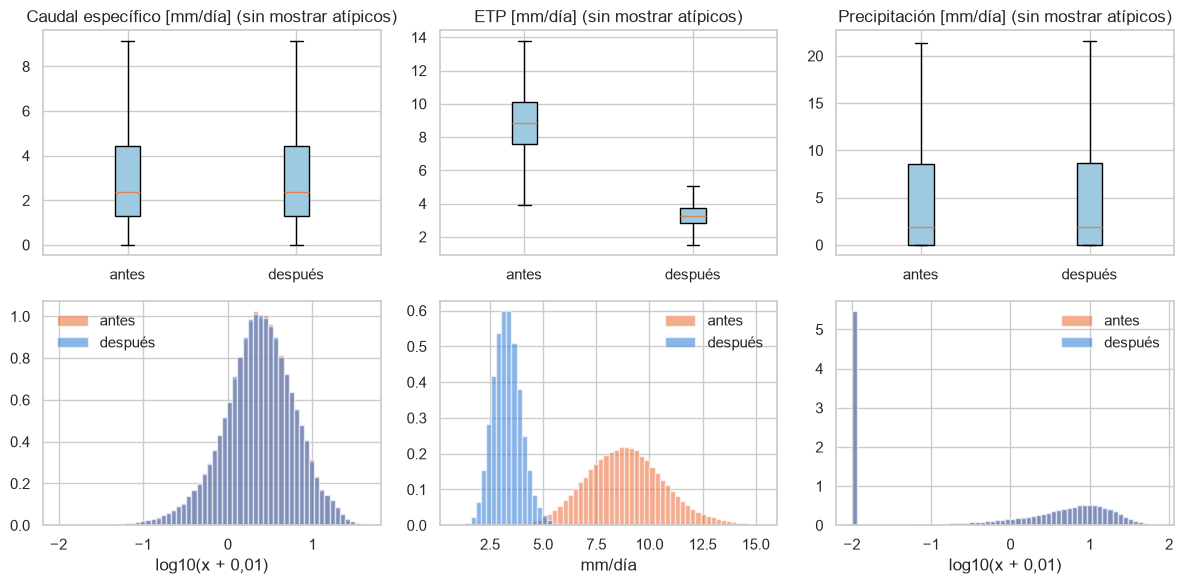

In [4]:
antes = {"q": [], "ETP": [], "P": []}; despues = {"q": [], "ETP": [], "P": []}
for g in est.index:
    a = pd.read_csv(RAW / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Precipitacion", "ETP_", "Caudal"])
    c = pd.read_csv(LIMPIAS / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Precipitacion", "ETP_", "Caudal"])
    f = 86.4 / areas[g]
    antes["q"].append((a.Caudal * f).values); despues["q"].append((c.Caudal * f).dropna().values)
    antes["ETP"].append(a.ETP_.values);       despues["ETP"].append(c.ETP_.dropna().values)
    antes["P"].append(a.Precipitacion.values); despues["P"].append(c.Precipitacion.dropna().values)
antes = {k: np.concatenate(v) for k, v in antes.items()}; despues = {k: np.concatenate(v) for k, v in despues.items()}

def atipicos_iqr(x):
    q1, q3 = np.percentile(x, [25, 75]); lim = (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
    return int(((x < lim[0]) | (x > lim[1])).sum())

NOMBRES = {"q": "Caudal específico [mm/día]", "ETP": "ETP [mm/día]", "P": "Precipitación [mm/día]"}
filas_t = []
for k in NOMBRES:
    for etiqueta, x in (("antes", antes[k]), ("después", despues[k])):
        n_at = atipicos_iqr(x)
        filas_t.append({"variable": NOMBRES[k], "versión": etiqueta, "días": len(x), "media": x.mean(), "mediana": np.median(x),
                        "p99": np.percentile(x, 99), "máximo": x.max(), "atípicos IQR": n_at, "% atípicos": 100 * n_at / len(x)})
display(pd.DataFrame(filas_t).set_index(["variable", "versión"]).round(2))

rng = np.random.default_rng(0)
mu = lambda x: rng.choice(x, 300_000, replace=False)
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for j, k in enumerate(NOMBRES):
    a_, d_ = mu(antes[k]), mu(despues[k])
    ax[0, j].boxplot([a_, d_], tick_labels=["antes", "después"], showfliers=False, patch_artist=True, boxprops=dict(facecolor="#9ecae1"))
    ax[0, j].set(title=NOMBRES[k] + " (sin mostrar atípicos)")
    tr = (lambda x: np.log10(x + 0.01)) if k != "ETP" else (lambda x: x)
    lim = (tr(np.minimum(a_, d_)).min(), np.percentile(tr(np.r_[a_, d_]), 99.9))
    ax[1, j].hist(tr(a_), bins=60, range=lim, alpha=.55, density=True, label="antes", color="#eb6834")
    ax[1, j].hist(tr(d_), bins=60, range=lim, alpha=.55, density=True, label="después", color="#2a78d6")
    ax[1, j].set(xlabel=("log10(x + 0,01)" if k != "ETP" else "mm/día")); ax[1, j].legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_limpieza_antes_despues.png", dpi=200); plt.show()

**Lectura.** La limpieza casi no cambia el caudal: toca 3.166 de 2,98 millones de días (0,1 %), deja igual la media (3,63 mm/día) y la mediana (2,38) y baja el máximo de 384 a 244 mm/día. El cambio grande está en la **ETP**: la media pasa de 8,91 a 3,29 mm/día y el percentil 99 de 13,9 a 5,0. La lluvia no se modifica.

Los atípicos por IQR del caudal (7,15 %) y de la lluvia (6,72 %) **no se eliminan**: son crecientes y aguaceros reales, y esa cola derecha es justo la señal que el producto debe estimar. La regla del IQR de [P1-A1] sirve para detectarlos, no para borrarlos; lo que sí se borra son los picos aislados de un día (`spike`), que no tienen ese respaldo.

### 2c. Un ejemplo: cuenca con más días marcados

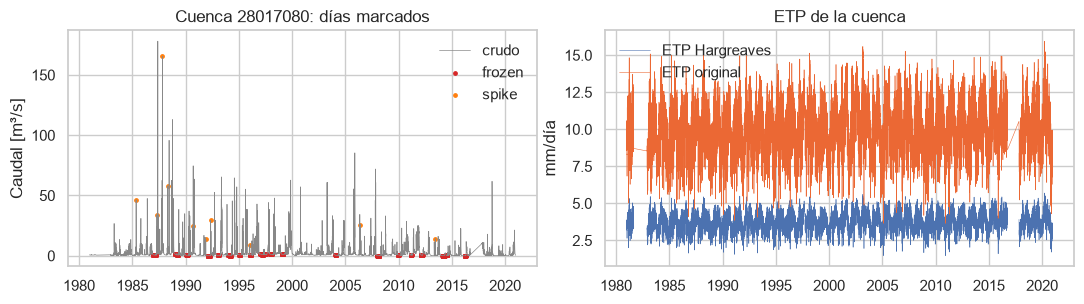

In [5]:
g = rep.assign(m=rep.frozen_dias + rep.spike_dias).sort_values("m").gauge_id.iloc[-1]
a = pd.read_csv(RAW / f"Hydromet_data_{g}.txt", sep="\t"); a["Fecha"] = pd.to_datetime(a.Fecha, format="%d/%m/%Y")
c = pd.read_csv(LIMPIAS / f"Hydromet_data_{g}.txt", sep="\t"); c["Fecha"] = pd.to_datetime(c.Fecha, format="%d/%m/%Y")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(a.Fecha, a.Caudal, lw=.5, color="#888", label="crudo")
for est_, col in [("frozen", "#d62728"), ("spike", "#ff7f0e")]:
    m = c.Caudal_estado == est_
    ax[0].scatter(c.Fecha[m], a.set_index("Fecha").Caudal.reindex(c.Fecha[m]).values, s=6, color=col, label=est_)
ax[0].set(title=f"Cuenca {g}: días marcados", ylabel="Caudal [m³/s]"); ax[0].legend(frameon=False)
ax[1].plot(c.Fecha, c.ETP_, lw=.4, label="ETP Hargreaves"); ax[1].plot(a.Fecha, a.ETP_, lw=.4, color="#eb6834", label="ETP original")
ax[1].set(title="ETP de la cuenca", ylabel="mm/día"); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_limpieza_ejemplo.png", dpi=200); plt.show()

## 3. Descarte de cuencas (6 banderas)
Una cuenca con cualquiera de las seis banderas se descarta. Código: `codigo/aplicar_banderas.py`. Respaldo y límites de cada una: sección 6 de `limpieza_series.ipynb`. `f_q_gt_p` y `f_flatline` se calculan; las otras cuatro son criterio del equipo.

Cuencas: 346   conservadas: 248   descartadas: 98


,cuencas con la bandera,solo esa bandera
f_q_gt_p,55,42
f_flatline,19,15
f_regime_mismatch,20,13
f_nested_inconsistent,13,9
f_delineation,6,0
f_twin_mismatch,5,3


,cuencas,conservadas,% conservadas
region,,,
Magdalena-Cauca,182,136,75
Orinoco,57,37,65
Caribe,53,44,83
Pacífico,32,20,62
Amazonas,22,11,50
Total,346,248,72


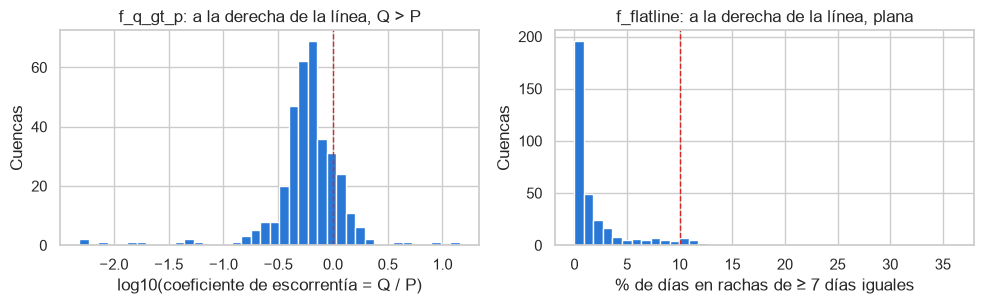

In [6]:
cols = ["f_q_gt_p", "f_flatline", "f_regime_mismatch", "f_nested_inconsistent", "f_delineation", "f_twin_mismatch"]
print(f"Cuencas: {len(B)}   conservadas: {int(B.conservada.sum())}   descartadas: {int((~B.conservada).sum())}")
display(pd.DataFrame({"cuencas con la bandera": B[cols].sum(), "solo esa bandera": [int(((B.n_banderas == 1) & B[c]).sum()) for c in cols]}))
r = B.groupby("region").agg(cuencas=("gauge_id", "count"), conservadas=("conservada", "sum")).reindex(ORDEN)
r["% conservadas"] = (100 * r.conservadas / r.cuencas).round(0); r.loc["Total"] = [r.cuencas.sum(), r.conservadas.sum(), round(100 * r.conservadas.sum() / r.cuencas.sum())]
display(r.astype(int))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(np.log10(B.coef_serie), bins=40, color="#2a78d6"); ax[0].axvline(0, color="#d62728", ls="--", lw=1)
ax[0].set(xlabel="log10(coeficiente de escorrentía = Q / P)", ylabel="Cuencas", title="f_q_gt_p: a la derecha de la línea, Q > P")
ax[1].hist(B.pct_rachas7, bins=40, color="#2a78d6"); ax[1].axvline(10, color="#d62728", ls="--", lw=1)
ax[1].set(xlabel="% de días en rachas de ≥ 7 días iguales", ylabel="Cuencas", title="f_flatline: a la derecha de la línea, plana")
fig.tight_layout(); fig.savefig(OUT / "fig_banderas.png", dpi=200); plt.show()

**Lectura.** Las dos banderas calculadas separan una cola de cuencas del resto: 55 cuencas a la derecha de la línea Q = P y 19 con 10 % o más de sus días en rachas planas. Las cifras por región y el respaldo de cada bandera están en `limpieza_series.ipynb`.

## 4. Valores faltantes e imputación
La clase [C1] (lám. 22) enseña imputar con la media, la mediana o la moda, por estrato o con KNN. Se evalúa si alguna sirve aquí, con datos, antes de decidir.

### 4a. Longitud de los vacíos de calendario
Un vacío es un tramo de días consecutivos que no aparecen en el archivo crudo. La cuestión es cuántos días faltantes están en vacíos cortos, porque solo esos se podrían rellenar con razonable confianza.

In [7]:
gaps = []
for g in B.gauge_id:
    nd = pd.read_csv(LIMPIAS / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Precipitacion"]).Precipitacion.isna().values
    d = np.diff(np.r_[0, nd.astype(int), 0]); ini, fin = np.where(d == 1)[0], np.where(d == -1)[0]
    gaps += list(fin - ini)
gaps = np.array(gaps)
cortes = [(1, 1, "1 día"), (2, 3, "2–3 días"), (4, 7, "4–7 días"), (8, 30, "8–30 días"), (31, 365, "31–365 días"), (366, 10**6, "más de 1 año")]
tg = pd.DataFrame([{"longitud del vacío": et, "vacíos": int(((gaps >= a) & (gaps <= b)).sum()), "días faltantes": int(gaps[(gaps >= a) & (gaps <= b)].sum())} for a, b, et in cortes]).set_index("longitud del vacío")
tg["% de los días faltantes"] = (100 * tg["días faltantes"] / tg["días faltantes"].sum()).round(1); tg["% acumulado"] = tg["% de los días faltantes"].cumsum().round(1)
display(tg)
print(f"Vacíos: {len(gaps):,}   días faltantes: {gaps.sum():,}   vacío más largo: {gaps.max():,} días")

,vacíos,días faltantes,% de los días faltantes,% acumulado
longitud del vacío,,,,
1 día,9673,9673,3.5,3.5
2–3 días,3814,8802,3.2,6.7
4–7 días,1686,8510,3.1,9.8
8–30 días,1647,26469,9.6,19.4
31–365 días,1342,142133,51.7,71.1
más de 1 año,119,79525,28.9,100.0


Vacíos: 18,281   días faltantes: 275,112   vacío más largo: 1,747 días


**Lectura.** Hay 18.281 vacíos y 275.112 días faltantes. Los vacíos cortos son muchos pero pesan poco: los de hasta 3 días son el 6,7 % de los días faltantes y los de hasta 30 días, el 19,4 %. El **80,6 % de los días faltantes está en vacíos de más de 30 días**, y 119 vacíos pasan de un año (el mayor, 1.747 días).

### 4b. ¿Qué tan bien imputaría cada técnica un vacío corto?
Se toma cada serie con dato, se borran al azar vacíos de 1, 2 y 3 días (2.000 por longitud y variable, en unas 30 cuencas) y se compara el valor real con dos imputaciones: la **mediana de la serie** (lo que enseña la clase) y la **interpolación lineal** entre los dos días vecinos. Se mide el error cuadrático medio (RMSE). Se prueba con la temperatura media (variable suave) y con la lluvia (variable intermitente).

In [8]:
rng = np.random.default_rng(42)
cuencas_sim = list(est.index[::8])
ser = {}
for g in cuencas_sim:
    s = pd.read_csv(LIMPIAS / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Precipitacion", "Temperatura_minima", "Temperatura_maxima"])
    ser[g] = {"Temperatura media [°C]": ((s.Temperatura_minima + s.Temperatura_maxima) / 2).values, "Lluvia [mm/día]": s.Precipitacion.values}
filas_s = []
for var in ("Temperatura media [°C]", "Lluvia [mm/día]"):
    for L in (1, 2, 3):
        e_med, e_lin = [], []
        for g in cuencas_sim:
            x = ser[g][var]; med = np.nanmedian(x)
            c = np.r_[0, np.cumsum(np.isnan(x))]; hay_nan = c[L + 2:] - c[:-(L + 2)]
            anclas = np.where(hay_nan == 0)[0] + 1
            for i in rng.choice(anclas, min(2000 // len(cuencas_sim) + 1, len(anclas)), replace=False):
                real = x[i:i + L]; t = np.arange(1, L + 1) / (L + 1)
                e_med += list(med - real); e_lin += list(x[i - 1] + t * (x[i + L] - x[i - 1]) - real)
        rm = lambda e: float(np.sqrt(np.mean(np.square(e))))
        filas_s.append({"variable": var, "vacío [días]": L, "RMSE mediana": rm(e_med), "RMSE interpolación": rm(e_lin), "mejora de la interpolación [%]": 100 * (1 - rm(e_lin) / rm(e_med))})
display(pd.DataFrame(filas_s).set_index(["variable", "vacío [días]"]).round(2))

RMSE mediana  RMSE interpolación  \
variable               vacío [días]                                     
Temperatura media [°C] 1                     0.98                0.60   
                       2                     0.97                0.66   
                       3                     0.96                0.71   
Lluvia [mm/día]        1                     9.04                8.86   
                       2                     9.47                9.67   
                       3                     9.42                9.87   

                                     mejora de la interpolación [%]  
variable               vacío [días]                                  
Temperatura media [°C] 1                                      38.46  
                       2                                      31.72  
                       3                                      26.27  
Lluvia [mm/día]        1                                       1.99  
                       2                                      -2.17  
                       3                                      -4.77

**Lectura.** La **temperatura** se interpola bien: el error baja de 0,96–0,98 °C con la mediana a 0,60–0,71 °C (26 a 38 % menos). La **lluvia** no mejora: con 1 día la interpolación gana solo 2 %, y con 2 y 3 días es peor que la mediana (2 y 5 %). Es esperable: la lluvia es intermitente y el día vecino no dice si llovió en el día del hueco.

### 4c. Decisión
**Series diarias: no se imputan.** (1) Solo el 6,7 % de los días faltantes está en vacíos de hasta 3 días, así que aun una imputación perfecta recuperaría poco; el 80,6 % está en vacíos de más de 30 días, donde no hay con qué rellenar. (2) La lluvia, que es la variable que más pesa, no mejora con interpolación ni con la mediana: inventar un valor mete un error que el modelo no distingue del dato real. (3) La temperatura sí se interpolaría bien (0,6 a 0,7 °C de error frente a 1,0), pero sin la lluvia la fila no se puede usar. El costo de no imputar, en filas perdidas, se mide en la sección 6.

**Atributos estáticos:** sin nulos (se comprueba abajo), pero el pipeline conserva la imputación con la mediana por si llega un atributo faltante en una cuenca nueva ([P6-A1]).

In [9]:
print(f"Nulos en los atributos de las 248 cuencas: {int(est.isna().sum().sum())}")

Nulos en los atributos de las 248 cuencas: 0


## 5. Atributos estáticos
Se unen las seis tablas de atributos (geología, cobertura, suelos, clima, fisiografía, uso del suelo) y se transforman con los criterios de [P1-A2].

| Paso | Regla |
|---|---|
| 1 | Solo las 248 cuencas |
| 2 | Se excluyen las **firmas hidrológicas** (archivo 09) y `q_mean`: salen del caudal observado y filtrarían el objetivo |
| 3 | Se quitan **duplicados** ([C1] lám. 17): `volcaniclastic_rock_perc`, `tc_chow`, `tc_Johnstone`, `tc_Engi_Corps`, `perimeter` |
| 4 | `aridez` con la ETP de Hargreaves reemplaza a `aridity` (que usa la ETP original) |
| 5 | Se quitan los atributos **constantes** en las 248 cuencas: no tienen información y la correlación no se puede calcular |
| 6 | Logaritmo a las variables continuas positivas con asimetría > 2: $\log x$ si todo es positivo y $\log(1+x/m)$, con $m$ la mediana de los positivos, si hay ceros. Los porcentajes se dejan |

### 5a. Redundancia antes y después
Matriz de correlación de Spearman entre atributos ([P1-A2]); se cuentan los pares con |ρ| ≥ 0,9.

Atributos antes: 59   después: 53   constantes quitados: ['coal_mine_pit_perc', 'class_1']
Pares con |ρ| ≥ 0,9: antes 25   después 6


,,|ρ| antes
tc_kirpich,tc_chow,1.000
tc_chow,tc_Johnstone,1.000
tc_kirpich,tc_Johnstone,1.000
volcanic_rock_perc,volcaniclastic_rock_perc,1.000
tc_kirpich,tc_Engi_Corps,0.995
tc_chow,tc_Engi_Corps,0.995
tc_Johnstone,tc_Engi_Corps,0.995
area,perimeter,0.991


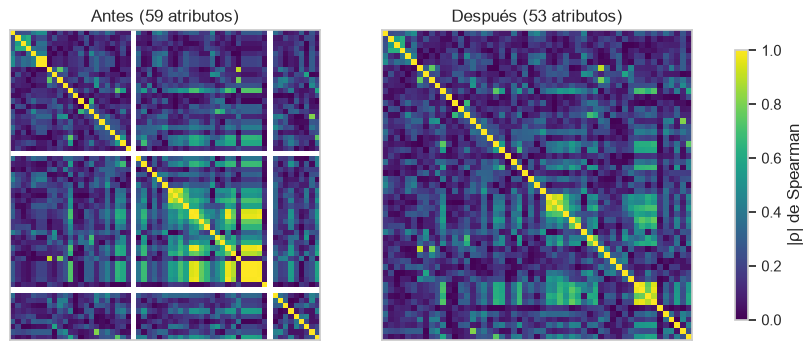

In [10]:
num = [c for c in est.columns if c != "region"]
partes = [pdat._leer("05_CAMELS_COL_Geologic_characteristics.csv"), pdat._leer("06_CAMELS_COL_Land_cover_characteristics.csv").rename(columns={"water_bodies_perc": "water_bodies_perc_cobertura"}),
          pdat._leer("07_CAMELS_COL_Soil_characteristics.csv").rename(columns={"water_bodies_perc": "water_bodies_perc_suelo"}), pdat._leer("08_CAMELS_COL_Climatic_indices.csv"),
          pdat._leer("10_CAMELS_COL_Physiograpic_characteristics.csv"), pdat._leer("11_CAMELS_COL_Land_use_capability.csv").dropna(how="all")]
partes[-1]["gauge_id"] = partes[-1]["gauge_id"].astype(int)
crudo = None
for p in partes: crudo = p if crudo is None else crudo.merge(p, on="gauge_id")
crudo["gauge_id"] = crudo.gauge_id.astype(int).astype(str); crudo = crudo.set_index("gauge_id").loc[est.index]
crudo = crudo.drop(columns=[c for c in ["aridity"] if c in crudo.columns])
def pares_altos(df, umbral=0.9):
    r = df.corr(method="spearman").abs(); p = r.where(np.triu(np.ones(r.shape), 1).astype(bool)).stack()
    return p[p >= umbral].sort_values(ascending=False)
antes_p, despues_p = pares_altos(crudo), pares_altos(est[num])
constantes = [c for c in crudo.columns if crudo[c].std() == 0]
print(f"Atributos antes: {crudo.shape[1]}   después: {len(num)}   constantes quitados: {constantes}")
print(f"Pares con |ρ| ≥ 0,9: antes {len(antes_p)}   después {len(despues_p)}")
display(antes_p.head(8).round(3).to_frame("|ρ| antes"))
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a_, df, tit in ((ax[0], crudo, f"Antes ({crudo.shape[1]} atributos)"), (ax[1], est[num], f"Después ({len(num)} atributos)")):
    im = a_.imshow(df.corr(method="spearman").abs(), cmap="viridis", vmin=0, vmax=1); a_.set_title(tit); a_.set_xticks([]); a_.set_yticks([])
fig.colorbar(im, ax=ax, shrink=.7, label="|ρ| de Spearman"); fig.savefig(OUT / "fig_correlacion_atributos.png", dpi=200); plt.show()

**Lectura.** Se pasa de 59 a 53 atributos: se quitan 5 duplicados (`volcaniclastic_rock_perc`, `tc_chow`, `tc_Johnstone`, `tc_Engi_Corps`, `perimeter`) y 2 constantes (`class_1`, `coal_mine_pit_perc`, iguales en las 248 cuencas) y se agrega `aridez`. Los pares con |ρ| ≥ 0,9 bajan de 25 a 6. Los 6 que quedan son de atributos del mismo tema (forma de la cuenca, frecuencias de lluvia, bosque y número de curva); no se eliminan más porque los árboles no se afectan y la regresión regularizada los maneja ([P1-A4]).

### 5b. Asimetría y logaritmo
Se mide la asimetría (*skewness*) de cada atributo continuo y se aplica el logaritmo a los positivos con asimetría > 2 ([P1-A3] usa Shapiro-Wilk para revisar la forma de una distribución; aquí además se reporta W, donde 1 es normal).

,transformación,asimetría antes,asimetría después,Shapiro W antes,Shapiro W después
atributo,,,,,
area,log(x),5.86,0.54,0.39,0.96
streng_chanel,log(x),2.72,0.69,0.60,0.95
equi_slope,log(x),2.52,0.14,0.74,0.96
tc_kirpich,log(x),2.34,0.49,0.65,0.96
tc_representative,log(x),3.35,0.61,0.63,0.97
class_2,log(1 + x/m),6.07,3.14,0.30,0.44
class_3,log(1 + x/m),3.73,1.08,0.61,0.86
class_5,log(1 + x/m),7.48,2.44,0.28,0.57
Urban_area,log(1 + x/m),9.89,1.54,0.26,0.81


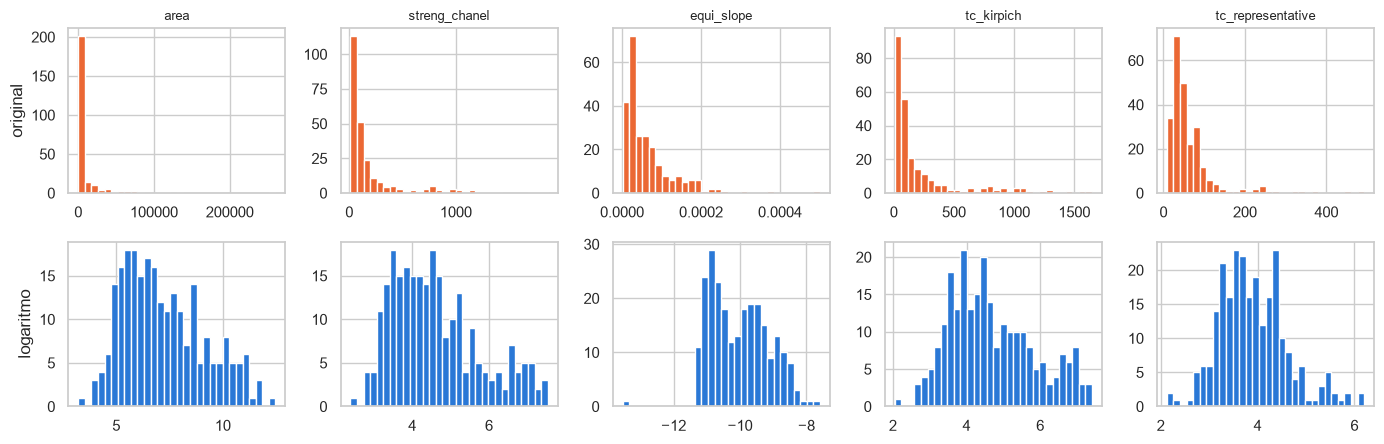

In [11]:
logs = [c for c in num if c.startswith(("log_", "log1p_"))]
base = lambda c: c.split("_", 1)[1] if c.startswith("log_") else c[6:]
orig = {c: crudo[base(c)] for c in logs}
tl = pd.DataFrame([{"atributo": base(c), "transformación": "log(x)" if c.startswith("log_") else "log(1 + x/m)", "asimetría antes": orig[c].skew(), "asimetría después": est[c].skew(),
                    "Shapiro W antes": stats.shapiro(orig[c])[0], "Shapiro W después": stats.shapiro(est[c])[0]} for c in logs]).set_index("atributo")
display(tl.round(2))
fig, ax = plt.subplots(2, 5, figsize=(14, 4.6))
for j, c in enumerate(logs[:5]):
    ax[0, j].hist(orig[c], bins=30, color="#eb6834"); ax[0, j].set_title(base(c), fontsize=9)
    ax[1, j].hist(est[c], bins=30, color="#2a78d6")
ax[0, 0].set_ylabel("original"); ax[1, 0].set_ylabel("logaritmo")
fig.tight_layout(); fig.savefig(OUT / "fig_log_atributos.png", dpi=200); plt.show()

**Lectura.** El logaritmo corrige bien las variables positivas continuas: el área baja de asimetría 5,86 a 0,54 (Shapiro W de 0,39 a 0,96), y `streng_chanel`, `tc_kirpich` y `tc_representative` quedan entre 0,5 y 0,7. **`equi_slope` mostró por qué hace falta la escala:** sus valores son de 1e-6 a 5e-4, y `log1p(x)` casi no la cambiaba (2,52 antes y después); con `log(x)` baja a 0,14. Las variables con ceros (`class_*`, `Urban_area`, `No_classified`) mejoran pero siguen asimétricas (`class_2` 3,14 y `class_5` 2,44), porque el problema es la masa de ceros y no la escala; se dejan así.

### 5c. Relación de los atributos con el caudal
Como en [P1-A2] y [P2-A2], se mide la relación de cada atributo con el objetivo. Aquí el objetivo por cuenca es el caudal específico medio (mm/día). Se usa Spearman y, para no encontrar relaciones por azar al probar muchos atributos, la corrección de Bonferroni ($\alpha = 0{,}05 / n$). Se grafican los cuatro más asociados.

53 atributos; α con Bonferroni = 0.0009; significativos: 27; |ρ| ≥ 0,3: 16


,rho,p,significativo (Bonferroni)
atributo,,,
aridez,-0.7806,0.0,True
mean_ele,-0.4940,0.0,True
forest_perc,0.4799,0.0,True
nat_non_forest_form_perc,-0.4555,0.0,True
low_prec_freq,-0.4325,0.0,True
high_prec_dur,-0.3824,0.0,True
low_prec_dur,-0.3802,0.0,True
high_prec_freq,-0.3775,0.0,True
minimum_ele,-0.3546,0.0,True


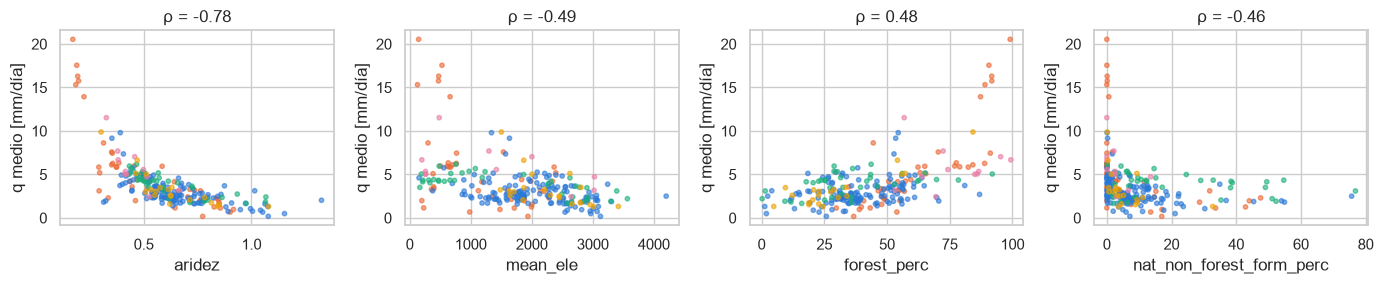

In [12]:
qm = {}
for g in est.index:
    q = pd.read_csv(LIMPIAS / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Caudal"]).Caudal * 86.4 / areas[g]
    qm[g] = q.mean()
q_medio = pd.Series(qm)
rho = pd.DataFrame([(c, *stats.spearmanr(est[c], q_medio)) for c in num], columns=["atributo", "rho", "p"]).set_index("atributo")
alfa = 0.05 / len(num); rho["significativo (Bonferroni)"] = rho.p < alfa
rho = rho.reindex(rho.rho.abs().sort_values(ascending=False).index)
print(f"{len(num)} atributos; α con Bonferroni = {alfa:.4f}; significativos: {int(rho['significativo (Bonferroni)'].sum())}; |ρ| ≥ 0,3: {int((rho.rho.abs() >= .3).sum())}")
display(rho.head(10).round(4))
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a_, c in zip(ax, rho.index[:4]):
    a_.scatter(est[c], q_medio, s=10, alpha=.6, c=[COLOR[r] for r in est.region]); a_.set(xlabel=c, ylabel="q medio [mm/día]", title=f"ρ = {rho.loc[c, 'rho']:.2f}")
fig.tight_layout(); fig.savefig(OUT / "fig_atributos_vs_caudal.png", dpi=200); plt.show()

**Lectura.** El atributo más asociado al caudal medio es la **aridez** (ρ = −0,78): a mayor aridez, menor caudal específico. Le siguen la elevación media (−0,49), el porcentaje de bosque (+0,48), la vegetación no boscosa (−0,46) y la frecuencia de lluvia baja (−0,43). De los 53 atributos, 27 son significativos con la corrección de Bonferroni (α = 0,0009) y 16 tienen |ρ| ≥ 0,3. Es una asociación entre cuencas, no una relación causal. Justifica incluir los atributos: sin ellos, el modelo no distinguiría una cuenca húmeda de una árida.

### 5d. ¿Importa la región? (justifica codificarla)
Prueba de Kruskal-Wallis, que no supone normalidad ([P2-A2] usa pruebas no paramétricas cuando la distribución lo exige), sobre el caudal medio por región. El tamaño del efecto es $\varepsilon^2=(H-k+1)/(n-k)$.

Kruskal-Wallis: H = 35.5, p = 3.7e-07, ε² = 0.13


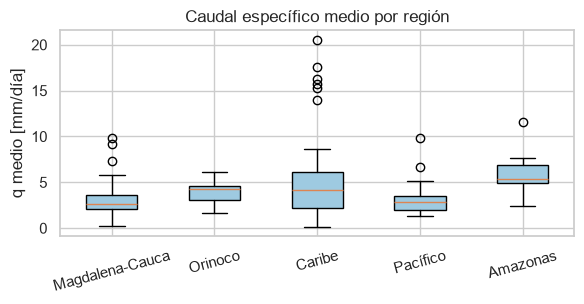

In [13]:
grupos = [q_medio[est.region == r] for r in ORDEN]
H, pH = stats.kruskal(*grupos); eps2 = (H - len(grupos) + 1) / (len(q_medio) - len(grupos))
print(f"Kruskal-Wallis: H = {H:.1f}, p = {pH:.1e}, ε² = {eps2:.2f}")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.boxplot(grupos, tick_labels=ORDEN, patch_artist=True, boxprops=dict(facecolor="#9ecae1")); ax.set(ylabel="q medio [mm/día]", title="Caudal específico medio por región"); plt.xticks(rotation=15)
fig.tight_layout(); fig.savefig(OUT / "fig_region_caudal.png", dpi=200); plt.show()
est.to_csv(OUT / "atributos_modelado.csv")

**Lectura.** La región sí importa: Kruskal-Wallis da H = 35,5 (p = 3,7e-7) con un efecto moderado (ε² = 0,13). Eso justifica conservar la región como variable y codificarla (sección 7a).

## 6. Variables de la serie (nuevas características)
Cada fila es una cuenca y un día. El objetivo es el **caudal específico** $q = Q\cdot 86{,}4/\text{área}$ [mm/día]. **No se usa el caudal de días anteriores:** el producto debe servir para cuencas sin estación. La memoria de la cuenca se representa con la lluvia acumulada.

| Variable | Cálculo | Por qué |
|---|---|---|
| `P` | lluvia del día [mm] | entrada directa |
| `P3`, `P7`, `P30`, `P90` | lluvia acumulada de los últimos 3, 7, 30 y 90 días | humedad y almacenamiento (se justifica en 6a) |
| `Tmean`, `Trango` | $(T_{min}+T_{max})/2$ y $T_{max}-T_{min}$ | el dataset no trae temperatura media |
| `ETP`, `ETP30` | Hargreaves del día y media de 30 días | demanda atmosférica |
| `sin_doy`, `cos_doy` | $\sin$ y $\cos$ de $2\pi\,\text{día del año}/365{,}25$ | estacionalidad anual sin salto entre diciembre y enero |
| `sin2_doy`, `cos2_doy` | lo mismo con $4\pi$ (dos ciclos por año) | regímenes con dos temporadas de lluvia (6c) |

### 6a. ¿Por qué esas ventanas de lluvia?
Para cada cuenca se calcula la correlación de Spearman entre $q$ y la lluvia acumulada en ventanas de 1 a 120 días, y se resume con la mediana entre cuencas. También se mide la correlación con la lluvia de $k$ días antes (rezago). Además se cuenta cuántas filas quedan con la ventana completa: **una ventana con algún `NaN` se descarta, no se imputa**.

,correlación mediana,p25,p75,% de los días con caudal que quedan
ventana [días],,,,
1,0.268,0.205,0.326,100.000
2,0.353,0.288,0.421,99.534
3,0.410,0.337,0.482,99.116
5,0.486,0.411,0.554,98.373
7,0.534,0.447,0.596,97.715
10,0.574,0.477,0.639,96.835
15,0.616,0.494,0.682,95.540
20,0.636,0.507,0.707,94.397
30,0.658,0.517,0.748,92.384


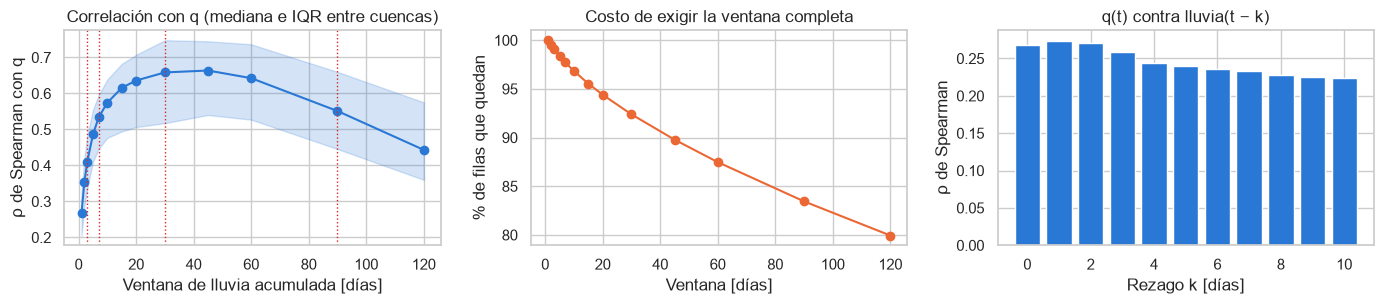

In [14]:
WIN = [1, 2, 3, 5, 7, 10, 15, 20, 30, 45, 60, 90, 120]
corr_w, n_w, corr_l, ok_dias = [], [], [], []
for g in est.index:
    s = pd.read_csv(LIMPIAS / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Precipitacion", "Caudal"])
    q, P = s.Caudal * 86.4 / areas[g], s.Precipitacion
    cw, nw = {}, {}
    for w in WIN:
        pw = P.rolling(w, min_periods=w).sum(); m = q.notna() & pw.notna()
        cw[w], nw[w] = q[m].corr(pw[m], method="spearman"), int(m.sum())
    cl = {}
    for k in range(0, 11):
        pk = P.shift(k); m = q.notna() & pk.notna(); cl[k] = q[m].corr(pk[m], method="spearman")
    corr_w.append(cw); n_w.append(nw); corr_l.append(cl); ok_dias.append(int(q.notna().sum()))
corr_w, n_w, corr_l = pd.DataFrame(corr_w, index=est.index), pd.DataFrame(n_w, index=est.index), pd.DataFrame(corr_l, index=est.index)
disp = 100 * n_w.sum() / sum(ok_dias)
tw = pd.DataFrame({"correlación mediana": corr_w.median(), "p25": corr_w.quantile(.25), "p75": corr_w.quantile(.75), "% de los días con caudal que quedan": disp})
tw.index.name = "ventana [días]"; display(tw.round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(WIN, tw["correlación mediana"], "o-", color="#2a78d6"); ax[0].fill_between(WIN, tw.p25, tw.p75, alpha=.2, color="#2a78d6")
for w in (3, 7, 30, 90): ax[0].axvline(w, color="#d62728", ls=":", lw=1)
ax[0].set(xlabel="Ventana de lluvia acumulada [días]", ylabel="ρ de Spearman con q", title="Correlación con q (mediana e IQR entre cuencas)")
ax[1].plot(WIN, disp, "o-", color="#eb6834"); ax[1].set(xlabel="Ventana [días]", ylabel="% de filas que quedan", title="Costo de exigir la ventana completa")
ax[2].bar(range(11), corr_l.median(), color="#2a78d6"); ax[2].set(xlabel="Rezago k [días]", ylabel="ρ de Spearman", title="q(t) contra lluvia(t − k)")
fig.tight_layout(); fig.savefig(OUT / "fig_ventanas_lluvia.png", dpi=200); plt.show()

**Lectura.** La correlación con el caudal **sube con la ventana y alcanza su máximo entre 30 y 45 días** (0,658 y 0,664), contra 0,27 para la lluvia de un día. Luego baja: 0,64 a 60 días, 0,55 a 90 y 0,44 a 120. La lluvia de hace *k* días se correlaciona de forma casi plana con el caudal (0,27 a 0,22 hasta 10 días): el caudal de hoy depende de la humedad acumulada más que de un día en particular.

**Decisión.** Se usan ventanas de 3, 7, 30 y 90 días para cubrir escalas distintas (evento, semana, mes, estación). Las de 30 y 45 días son las mejores por sí solas; 90 correlaciona menos (0,55) y cuesta más filas (quedan 83,4 % frente a 92,4 % con 30 días), pero aporta memoria de otra escala. No se agregan más ventanas para no sumar variables casi iguales ni perder más filas. No se probó el aporte conjunto de cada ventana; eso lo mostrará el modelo.

### 6b. Tabla de variables y relación entre ellas
Se arma la tabla de filas utilizables de las 248 cuencas (día con caudal `ok` y todas las variables completas) y se calcula la matriz de correlación de Spearman entre las variables y el caudal ([P1-A2]).

Filas utilizables: 2,483,808 de 2,976,524 días con caudal ok (492,716 descartadas, 16.6 %)


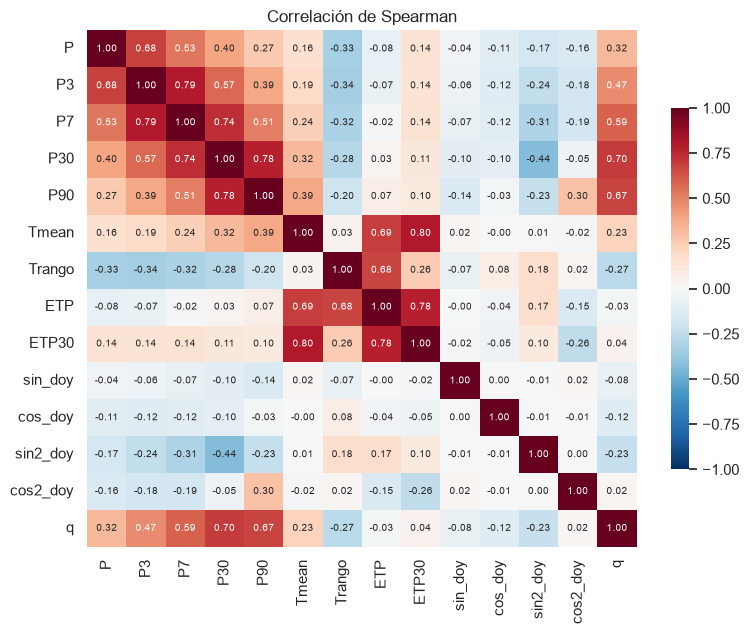

Correlación de cada variable con q:


,ρ con q
P30,0.701
P90,0.674
P7,0.588
P3,0.473
P,0.323
Trango,-0.267
sin2_doy,-0.228
Tmean,0.228
cos_doy,-0.121
sin_doy,-0.078


In [15]:
filas, resumen = pdat.construir_filas(est, areas)
perdidas = int((resumen.dias_ok - resumen.filas_utiles).sum())
print(f"Filas utilizables: {len(filas):,} de {int(resumen.dias_ok.sum()):,} días con caudal ok ({perdidas:,} descartadas, {100 * perdidas / resumen.dias_ok.sum():.1f} %)")
mu_f = filas.sample(300_000, random_state=0)
cm = mu_f[pdat.DINAMICAS + ["q"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .7}); ax.set_title("Correlación de Spearman")
fig.tight_layout(); fig.savefig(OUT / "fig_correlacion_variables.png", dpi=200); plt.show()
print("Correlación de cada variable con q:"); display(cm["q"].drop("q").sort_values(key=abs, ascending=False).round(3).to_frame("ρ con q"))

**Lectura.** Las variables más asociadas al caudal son los acumulados de lluvia: `P30` (ρ = 0,70), `P90` (0,67), `P7` (0,59) y `P3` (0,47), contra 0,32 de la lluvia del día. Siguen el rango de temperatura (−0,27), el segundo armónico estacional (−0,23) y la temperatura media (0,23). **La ETP casi no se relaciona con el caudal** (|ρ| < 0,05). Se conserva porque su efecto puede depender de la lluvia (una ETP alta importa si llueve poco), pero es candidata a descartar si el modelo no la usa. Estas correlaciones juntan todas las cuencas, así que mezclan diferencias entre cuencas con diferencias en el tiempo.

### 6c. Estacionalidad
`sin_doy` y `cos_doy` codifican el día del año como un punto de un círculo, de modo que el 31 de diciembre queda junto al 1 de enero (con el día del año como número, quedarían en extremos opuestos). Se comprueba, por región, cuánto del ciclo del caudal captura el primer armónico (un ciclo al año) y el segundo (dos ciclos), que debería ayudar donde hay dos temporadas de lluvia.

,"corr(q, sin_doy)","corr(q, cos_doy)","corr(q, sin2_doy)","corr(q, cos2_doy)"
Magdalena-Cauca,0.00,-0.02,-0.21,-0.02
Orinoco,-0.24,-0.54,-0.08,0.14
Caribe,-0.11,-0.03,-0.11,0.01
Pacífico,0.13,0.21,-0.14,0.09
Amazonas,-0.03,-0.30,-0.08,0.08


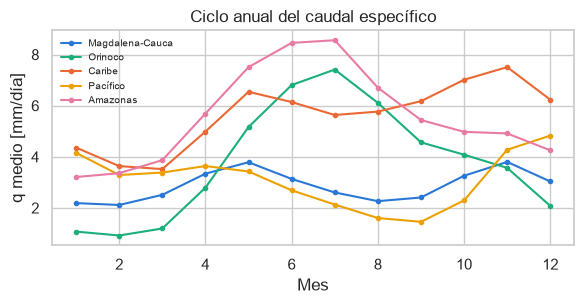

In [16]:
f2 = filas.assign(mes=filas.Fecha.dt.month, region=filas.gauge_id.map(est.region))
ciclo = f2.groupby(["region", "mes"]).q.mean().unstack(0)[ORDEN]
armonicos = ["sin_doy", "cos_doy", "sin2_doy", "cos2_doy"]
corr_est = pd.DataFrame({r: {f"corr(q, {a})": f2[f2.region == r].q.corr(f2[f2.region == r][a]) for a in armonicos} for r in ORDEN}).T
display(corr_est.round(2))
fig, ax = plt.subplots(figsize=(6, 3.2))
for r in ORDEN: ax.plot(range(1, 13), ciclo[r], "o-", ms=3, label=r, color=COLOR[r])
ax.set(xlabel="Mes", ylabel="q medio [mm/día]", title="Ciclo anual del caudal específico"); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "fig_ciclo_anual.png", dpi=200); plt.show()

**Lectura.** El primer armónico (un ciclo al año) explica el caudal donde hay una sola temporada de lluvia: en el Orinoco la correlación con `cos_doy` es −0,54 y en el Amazonas −0,30. **En Magdalena-Cauca y Caribe, que tienen dos temporadas, el ciclo anual no sirve** (≈ 0 y −0,11), y el segundo armónico recupera una parte en Magdalena-Cauca (`sin2_doy`, −0,21). Por eso se agregan `sin2_doy` y `cos2_doy`. Son correlaciones lineales: un modelo no lineal combinará estas variables con la lluvia acumulada y sacará más de ellas.

### 6d. Distribución de las variables
Histogramas y asimetría de las variables de entrada ([P1-A1]).

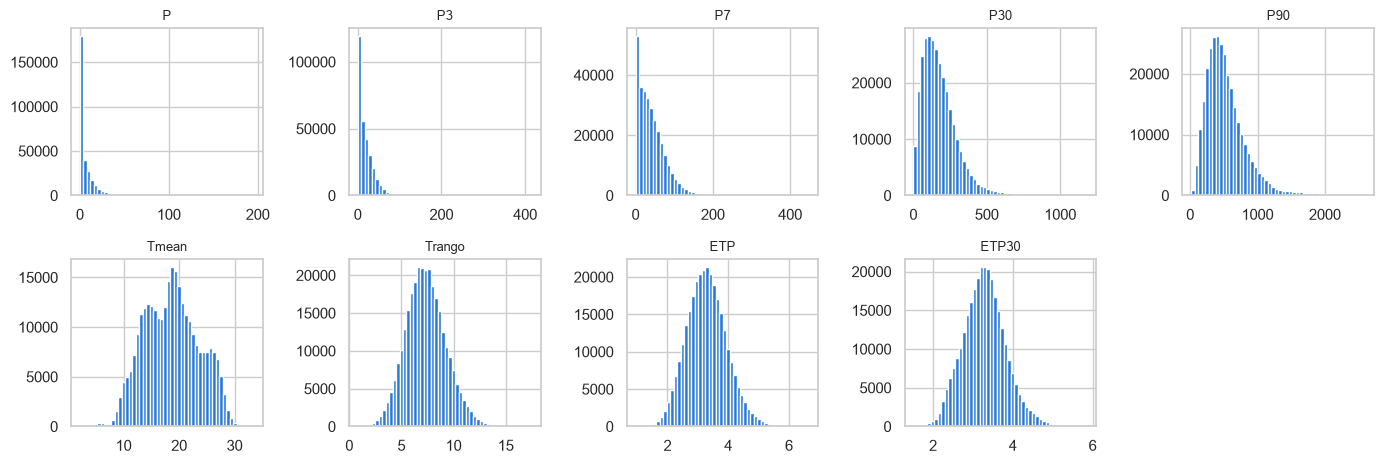

,mean,std,skew,min,max
P,5.94,9.30,2.94,0.00,195.87
P3,17.82,18.88,1.78,0.00,416.05
P7,41.52,35.14,1.37,0.00,450.46
P30,177.59,118.36,1.33,0.00,1185.56
P90,531.36,306.95,1.57,15.03,2600.19
Tmean,18.59,4.94,0.06,2.12,33.50
Trango,7.32,1.93,0.26,0.81,17.50
ETP,3.29,0.66,0.30,0.95,6.68
ETP30,3.28,0.54,0.29,1.51,5.87


In [17]:
vars_h = ["P", "P3", "P7", "P30", "P90", "Tmean", "Trango", "ETP", "ETP30"]
fig, ax = plt.subplots(2, 5, figsize=(14, 4.8))
for a_, v in zip(ax.flat, vars_h):
    a_.hist(mu_f[v], bins=50, color="#2a78d6"); a_.set_title(v, fontsize=9)
for a_ in ax.flat[len(vars_h):]: a_.axis("off")
fig.tight_layout(); fig.savefig(OUT / "fig_distribucion_variables.png", dpi=200); plt.show()
display(mu_f[vars_h].agg(["mean", "std", "skew", "min", "max"]).T.round(2))

**Lectura.** La lluvia diaria es muy asimétrica (asimetría 2,94, con muchos días sin lluvia) y los acumulados lo son menos (1,3 a 1,8). La temperatura y la ETP son casi simétricas (0,06 a 0,30). **No se transforma la lluvia:** los días en cero son información (no llovió) y un logaritmo los mezclaría con los días de poca lluvia; la estandarización de la sección 7 deja las variables en una escala común.

## 7. Codificación y estandarización
Mismo esquema de [P6-A1]: un `ColumnTransformer` con dos ramas. **Numéricas:** `SimpleImputer(median)` y `StandardScaler`, que lleva cada variable a media 0 y desviación 1: $z=(x-\bar x)/s$. **Región:** `SimpleImputer(most_frequent)` y `OneHotEncoder`. Se **ajusta solo con el primer 60 % cronológico de cada cuenca** (la partición completa está en `validacion_particion.ipynb`), para que ninguna estadística de los días posteriores entre al ajuste.

### 7a. Codificación de la región
La región es una categoría sin orden, así que se codifica con una columna binaria por región (one-hot) y no con un número 1 a 5, que sugeriría un orden que no existe.

In [18]:
col_num, col_cat = pdat.columnas(est)
muestra, _ = pdat.construir_filas(est, areas, n_por_cuenca_train=600)
train = pdat.agregar_estaticos(muestra[muestra.particion == "entrenamiento"], est)
pre = pdat.crear_preprocesamiento(col_num, col_cat).fit(train[col_num + col_cat])
nombres = list(pre.get_feature_names_out())
reg_cols = [n for n in nombres if n.startswith("categoricas__")]
Xt = pre.transform(train[col_num + col_cat]); Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
print(f"Muestra de ajuste: {len(train):,} filas de {train.gauge_id.nunique()} cuencas (hasta 600 por cuenca)")
print(f"Entrada: {len(col_num)} numéricas + región  →  salida: {Xt.shape[1]} columnas")
display(pd.DataFrame({"columna": reg_cols, "cuencas": [int((est.region == c.replace('categoricas__region_', '')).sum()) for c in reg_cols],
                      "filas con valor 1": [int(Xt[:, nombres.index(c)].sum()) for c in reg_cols]}).set_index("columna"))

Muestra de ajuste: 148,800 filas de 248 cuencas (hasta 600 por cuenca)
Entrada: 66 numéricas + región  →  salida: 71 columnas


,cuencas,filas con valor 1
columna,,
categoricas__region_Amazonas,11,6600
categoricas__region_Caribe,44,26400
categoricas__region_Magdalena-Cauca,136,81600
categoricas__region_Orinoco,37,22200
categoricas__region_Pacífico,20,12000


**Lectura.** La región queda en 5 columnas binarias, una por región, con tantas filas en 1 como cuencas tiene la región por 600 días (Magdalena-Cauca 81.600, Caribe 26.400, Orinoco 22.200, Pacífico 12.000, Amazonas 6.600). El Amazonas, con 11 cuencas, tiene poco peso en el ajuste; sus resultados serán indicativos.

### 7b. Estandarización: antes y después
Se compara el rango de cada variable antes del escalado (las escalas son muy distintas: el área, la lluvia y las pendientes no son comparables) con el resultado, usando cajas ([P1-A1]) y la tabla de estadísticos. Un modelo basado en distancias o gradientes, como la regresión regularizada o la red neuronal, se distorsiona si una variable tiene una escala mucho mayor que las demás.

antes                           después                
                min      max     mean     std     min   max mean  std
log_area       3.22    12.47     7.21    1.91   -2.09  2.75  0.0  1.0
mean_ele     126.95  4200.99  1800.73  868.84   -1.93  2.76 -0.0  1.0
forest_perc    0.21    99.33    43.15   20.73   -2.07  2.71 -0.0  1.0
aridez         0.17     1.33     0.61    0.19   -2.28  3.69 -0.0  1.0
P30            0.00  1062.79   180.47  119.98   -1.50  7.35  0.0  1.0
Tmean          2.81    33.04    18.63    4.91   -3.22  2.93 -0.0  1.0

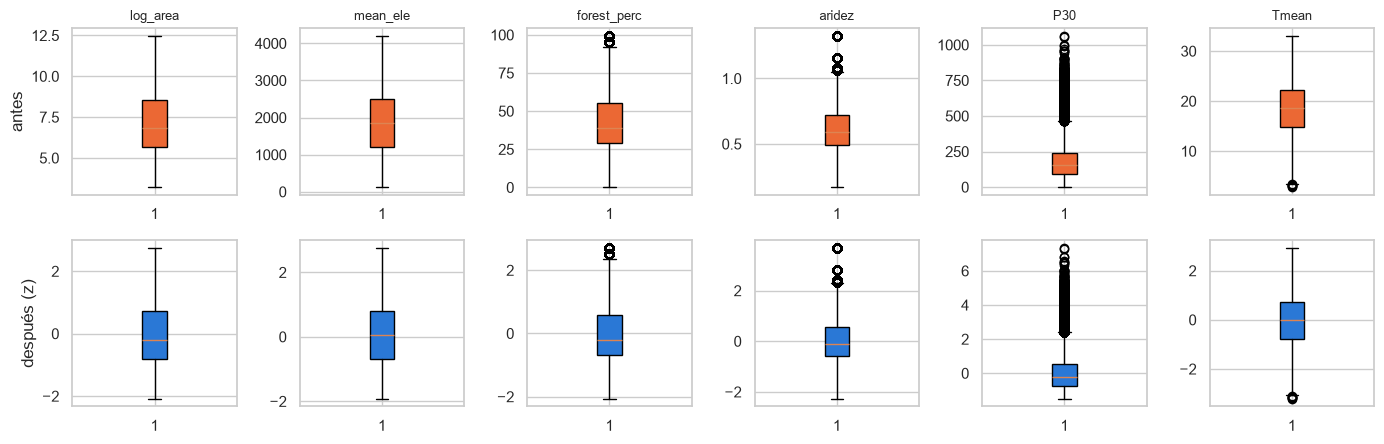

Todas las columnas numéricas: media -0.000, desviación 1.000


In [19]:
demo = ["log_area", "mean_ele", "forest_perc", "aridez", "P30", "Tmean"]
ant = train[demo]; z = pd.DataFrame(Xt[:, [nombres.index(f"numericas__{v}") for v in demo]], columns=demo)
display(pd.concat({"antes": ant.agg(["min", "max", "mean", "std"]).T, "después": z.agg(["min", "max", "mean", "std"]).T}, axis=1).round(2))
fig, ax = plt.subplots(2, 6, figsize=(14, 4.6))
for j, v in enumerate(demo):
    ax[0, j].boxplot(ant[v], patch_artist=True, boxprops=dict(facecolor="#eb6834")); ax[0, j].set_title(v, fontsize=9)
    ax[1, j].boxplot(z[v], patch_artist=True, boxprops=dict(facecolor="#2a78d6"))
ax[0, 0].set_ylabel("antes"); ax[1, 0].set_ylabel("después (z)")
fig.tight_layout(); fig.savefig(OUT / "fig_estandarizacion.png", dpi=200); plt.show()
print(f"Todas las columnas numéricas: media {Xt[:, :len(col_num)].mean():.3f}, desviación {Xt[:, :len(col_num)].std():.3f}")

**Lectura.** Antes del escalado las variables están en escalas incomparables (la elevación va de 127 a 4.201, la lluvia de 30 días de 0 a 1.063 y la aridez de 0,17 a 1,33). Después, todas quedan con media 0 y desviación 1; el máximo de `P30` (7,35) refleja su cola derecha de lluvias extremas, que no se recorta.

### 7c. ¿Por qué ajustar solo con el 60 % inicial?
La pregunta de la clase ([P6-A1]) es por qué el escalado se ajusta antes de ver el resto de los datos. Se mide cuánto cambiarían la media y la desviación si el ajuste usara también validación y prueba: desplazamiento $(\bar x_{todo}-\bar x_{entren})/s_{entren}$.

In [20]:
todo = pdat.agregar_estaticos(filas.sample(300_000, random_state=0), est)[col_num]
desp = ((todo.mean() - train[col_num].mean()) / train[col_num].std()).abs().sort_values(ascending=False)
print(f"Desplazamiento máximo de la media: {desp.iloc[0]:.2f} desviaciones; mediana {desp.median():.3f}")
display(desp.head(6).round(3).to_frame("|desplazamiento| (en desviaciones)"))
joblib.dump({"preprocesamiento": pre, "col_num": col_num, "col_cat": col_cat}, OUT / "preprocesamiento.joblib")
print("Guardado:", OUT / "preprocesamiento.joblib")

Desplazamiento máximo de la media: 0.07 desviaciones; mediana 0.019


,|desplazamiento| (en desviaciones)
cn_catchment,0.070
forest_perc,0.064
high_prec_freq,0.058
low_prec_freq,0.058
agricul_livestock_perc,0.056
Trango,0.054


Guardado: C:\Users\js.rodrigueza1\Documents\Proyectos 1\Ciencia de datos\salidas\datos_preparados\preprocesamiento.joblib


**Lectura.** Ajustar el escalado con todos los datos, y no solo con el 60 % inicial, movería las medias muy poco: a lo sumo 0,07 desviaciones (mediana 0,019). En estos datos el efecto sería pequeño, pero la regla se mantiene porque es la práctica correcta ([P6-A1]) y garantiza que ningún dato de los días de prueba influya en el preprocesamiento.

## 8. Datos para el dashboard
El producto muestra cada cuenca en un mapa, con su serie diaria y un aviso de calidad. Se prepara una tabla con **las 346 cuencas** (también las descartadas, para poder avisar que no son confiables): ubicación en grados, región, área, periodo con caudal válido, días marcados y estado con su motivo. La serie diaria que mostrará el dashboard es la limpia (`salidas/series_limpias/`), con `Caudal_estado` para señalar los días sin dato.

Tabla para el dashboard: 346 cuencas, 15 columnas → tabla_dashboard_cuencas.csv


,cuencas
aviso_calidad,
Sin avisos,202
Cuenca descartada por calidad de datos,98
Más del 10 % de los días sin caudal válido,46


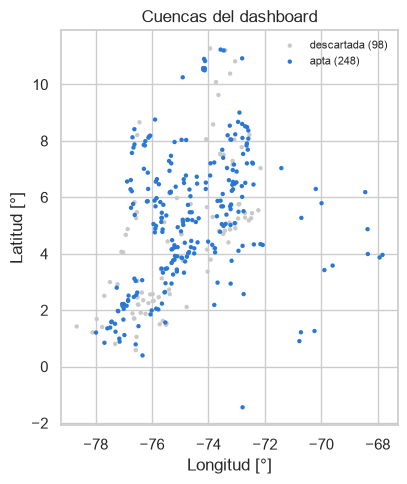

,departamento,lat,lon,elevacion_m,area_km2,region,anio_inicio_caudal,anio_fin_caudal,dias_caudal_valido,q_valido_pct,spike_dias,frozen_dias,estado,motivo_descarte,aviso_calidad
gauge_id,,,,,,,,,,,,,,,
11017010,Choco,5.473944,-76.537861,78,891.98,Caribe,1981,2022,14444,95.01,0,0,descartada,f_q_gt_p,Cuenca descartada por calidad de datos: f_q_gt_p
11027010,Choco,5.851972,-76.180806,1499,205.01,Caribe,1981,2001,7211,95.27,1,0,apta,,Sin avisos
11027030,Choco,5.862000,-76.152056,1568,195.54,Caribe,1981,2022,14906,97.17,0,0,apta,,Sin avisos


In [21]:
from pyproj import Transformer
info = pd.read_csv(RAIZ / "Camels col/02_CAMELS_COL_Catchment_information.csv", sep=";", encoding="latin-1")
lon, lat = Transformer.from_crs("ESRI:54004", "EPSG:4326", always_xy=True).transform(info.gauge_lon.values, info.gauge_lat.values)
tab = pd.DataFrame({"gauge_id": info.gauge_id.astype(str), "departamento": info.gauge_department, "lat": lat, "lon": lon, "elevacion_m": info.gauge_elev}).set_index("gauge_id")
fis = pd.read_csv(RAIZ / "Camels col/10_CAMELS_COL_Physiograpic_characteristics.csv", sep=";"); fis.columns = fis.columns.str.strip()
fis["gauge_id"] = fis.gauge_id.astype(int).astype(str)
tab["area_km2"] = fis.set_index("gauge_id").area
tab["region"] = [pdat.REGIONES[g[0]] for g in tab.index]
ini, fin, dias = {}, {}, {}
for g in tab.index:
    s = pd.read_csv(LIMPIAS / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Fecha", "Caudal_estado"])
    f = pd.to_datetime(s.Fecha[s.Caudal_estado == "ok"], format="%d/%m/%Y")
    ini[g], fin[g], dias[g] = f.min().year, f.max().year, len(f)
tab["anio_inicio_caudal"], tab["anio_fin_caudal"], tab["dias_caudal_valido"] = pd.Series(ini), pd.Series(fin), pd.Series(dias)
tab = tab.join(rep.set_index("gauge_id")[["q_valido_pct", "spike_dias", "frozen_dias"]])
Bi = B.set_index("gauge_id")
tab["estado"] = np.where(Bi.conservada, "apta", "descartada")
tab["motivo_descarte"] = Bi[cols].apply(lambda r: ", ".join(c for c in cols if r[c]), axis=1)
tab["aviso_calidad"] = np.where(~Bi.conservada, "Cuenca descartada por calidad de datos: " + tab.motivo_descarte,
                                np.where(tab.q_valido_pct < 90, "Más del 10 % de los días sin caudal válido", "Sin avisos"))
tab.round(3).to_csv(OUT / "tabla_dashboard_cuencas.csv")
print(f"Tabla para el dashboard: {len(tab)} cuencas, {tab.shape[1]} columnas → tabla_dashboard_cuencas.csv")
display(tab.aviso_calidad.str.split(":").str[0].value_counts().to_frame("cuencas"))
fig, ax = plt.subplots(figsize=(4.8, 5))
for est_, col in [("descartada", "#c9c9c9"), ("apta", "#2a78d6")]:
    m = tab[tab.estado == est_]; ax.scatter(m.lon, m.lat, s=10, c=col, label=f"{est_} ({len(m)})", edgecolor="none")
ax.set(xlabel="Longitud [°]", ylabel="Latitud [°]", title="Cuencas del dashboard"); ax.set_aspect("equal"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "fig_mapa_cuencas.png", dpi=200); plt.show()
tab.head(3)

**Lectura.** De las 346 cuencas, 202 no tienen avisos, 46 son aptas pero con más del 10 % de días sin caudal válido y 98 están descartadas, con su motivo. Así el dashboard puede mostrar siempre la cuenca y advertir cuándo no es confiable.

## 9. Resultado
### 9a. Tabla preparada
Muestra de la tabla que entra al modelo (un día de una cuenca por fila), ya transformada.

In [22]:
Xdf = pd.DataFrame(Xt, columns=[n.split("__")[1] for n in nombres])
print(f"Matriz preparada de ajuste: {Xdf.shape[0]:,} filas × {Xdf.shape[1]} columnas; nulos: {int(np.isnan(Xt).sum())}")
Xdf.iloc[:, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]].head(5).round(2)

Matriz preparada de ajuste: 148,800 filas × 71 columnas; nulos: 0


,P,P3,P7,P30,P90,Tmean,Trango,ETP,ETP30,sin_doy,cos_doy,sin2_doy,cos2_doy,unconso_depo_perc
0,-0.57,-0.35,-0.47,0.30,-0.08,-0.40,-0.36,-0.22,-0.90,1.42,0.05,0.08,-1.41,-0.22
1,-0.55,1.51,1.38,0.16,0.08,-0.49,-1.60,-1.25,-0.79,1.41,-0.17,-0.36,-1.36,-0.22
2,1.86,1.17,1.62,0.30,0.21,-0.41,-2.36,-1.94,-0.80,1.40,-0.25,-0.50,-1.31,-0.22
3,2.42,1.79,1.75,1.73,0.95,-0.56,-1.60,-1.33,-1.06,1.29,-0.59,-1.08,-0.89,-0.22
4,-0.43,0.78,1.36,1.68,0.95,-0.38,-0.88,-0.66,-1.12,1.27,-0.64,-1.14,-0.81,-0.22


### 9b. Diccionario de las variables preparadas

In [23]:
xl = pd.read_excel(RAIZ / "Camels col/01_CAMELS_COL_Attributes/01_CAMELS_COL_Attributes/01_CAMELS_COL_Attributes.xlsx", sheet_name="Plan1")
xl.columns = ["clase", "variable", "descripcion", "unidades", "fuente"][:xl.shape[1]]
xl["variable"] = xl["variable"].astype(str).str.strip(); xl = xl.drop_duplicates("variable").set_index("variable")
ORIGEN = {}
for archivo, nombre in [("05_CAMELS_COL_Geologic_characteristics.csv", "05 Geología"), ("06_CAMELS_COL_Land_cover_characteristics.csv", "06 Cobertura"), ("07_CAMELS_COL_Soil_characteristics.csv", "07 Suelos"),
                        ("08_CAMELS_COL_Climatic_indices.csv", "08 Clima"), ("10_CAMELS_COL_Physiograpic_characteristics.csv", "10 Fisiografía"), ("11_CAMELS_COL_Land_use_capability.csv", "11 Uso del suelo")]:
    for c in pdat._leer(archivo).columns: ORIGEN[c] = nombre
DIN = {"P": ("mm", "lluvia del día (CHIRPS)"), "P3": ("mm", "lluvia acumulada 3 días"), "P7": ("mm", "lluvia acumulada 7 días"), "P30": ("mm", "lluvia acumulada 30 días"),
       "P90": ("mm", "lluvia acumulada 90 días"), "Tmean": ("°C", "(Tmin + Tmax) / 2"), "Trango": ("°C", "Tmax − Tmin"), "ETP": ("mm/día", "Hargreaves del día"),
       "ETP30": ("mm/día", "media de 30 días de la ETP"), "sin_doy": ("—", "seno del día del año (1 ciclo)"), "cos_doy": ("—", "coseno del día del año (1 ciclo)"),
       "sin2_doy": ("—", "seno del día del año (2 ciclos)"), "cos2_doy": ("—", "coseno del día del año (2 ciclos)")}
filas_d = []
for v in col_num:
    v0 = base(v) if v.startswith(("log_", "log1p_")) else v
    d_xl = xl.descripcion.get(v0, "") if v0 in xl.index else ""
    u_xl = xl.unidades.get(v0, "") if v0 in xl.index else ""
    if v in DIN: tipo, uni, desc, ori = "dinámica (diaria)", DIN[v][0], DIN[v][1], "series_limpias"
    elif v == "aridez": tipo, uni, desc, ori = "estática", "—", "ETP de Hargreaves / lluvia media", "series_limpias"
    elif v.startswith("log_"): tipo, uni, desc, ori = "estática", "log", f"log({v0}): {d_xl}", ORIGEN.get(v0, "")
    elif v.startswith("log1p_"): tipo, uni, desc, ori = "estática", "log", f"log(1 + {v0}/m), m = mediana de los positivos: {d_xl}", ORIGEN.get(v0, "")
    else: tipo, uni, desc, ori = "estática", u_xl, d_xl, ORIGEN.get(v, "")
    filas_d.append({"variable": v, "tipo": tipo, "unidad": uni, "descripción": desc, "origen": ori, "mín": train[v].min(), "mediana": train[v].median(), "máx": train[v].max()})
filas_d.append({"variable": "region", "tipo": "categórica", "unidad": "—", "descripción": "región (primer dígito del código de la estación), one-hot", "origen": "código IDEAM", "mín": np.nan, "mediana": np.nan, "máx": np.nan})
dicc = pd.DataFrame(filas_d).set_index("variable"); dicc.round(3).to_csv(OUT / "diccionario_variables_preparadas.csv")
print(f"{len(dicc)} variables de entrada ({len(col_num)} numéricas + región); objetivo: q = Q · 86,4 / área [mm/día]")
display(dicc.round(2).head(20))

67 variables de entrada (66 numéricas + región); objetivo: q = Q · 86,4 / área [mm/día]


,tipo,unidad,descripción,origen,mín,mediana,máx
variable,,,,,,,
P,dinámica (diaria),mm,lluvia del día (CHIRPS),series_limpias,0.00,2.04,167.09
P3,dinámica (diaria),mm,lluvia acumulada 3 días,series_limpias,0.00,13.03,269.93
P7,dinámica (diaria),mm,lluvia acumulada 7 días,series_limpias,0.00,34.75,445.85
P30,dinámica (diaria),mm,lluvia acumulada 30 días,series_limpias,0.00,157.43,1062.79
P90,dinámica (diaria),mm,lluvia acumulada 90 días,series_limpias,16.54,475.79,2570.33
Tmean,dinámica (diaria),°C,(Tmin + Tmax) / 2,series_limpias,2.81,18.52,33.04
Trango,dinámica (diaria),°C,Tmax − Tmin,series_limpias,0.72,7.13,16.94
ETP,dinámica (diaria),mm/día,Hargreaves del día,series_limpias,0.81,3.24,6.45
ETP30,dinámica (diaria),mm/día,media de 30 días de la ETP,series_limpias,1.48,3.25,5.77


### 9c. Lo que pide el ítem 8

| Lo que pide la rúbrica | Dónde |
|---|---|
| Describir el proceso | todo el notebook y el diagrama de abajo |
| Evidencia de los datos preparados | tablas y figuras de cada sección; 9a |
| Creación de nuevas características | sección 6 (lluvia acumulada, temperatura media y rango, ETP de 30 días, estacionalidad con dos armónicos) y sección 5 (logaritmo, aridez) |
| Codificación de variables categóricas | sección 7a (one-hot de la región) |
| Normalización y estandarización | sección 7b (`StandardScaler`) |
| Imputación de datos faltantes | secciones 4 y 7 |
| Diagrama de bloques | a continuación |

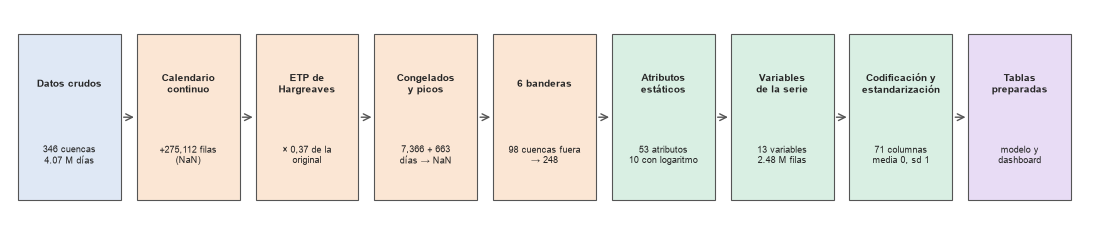

In [24]:
n_crudo = int((rep.dias - rep.dias_agregados).sum())
pasos = [("Datos crudos", f"{len(rep)} cuencas\n{n_crudo/1e6:.2f} M días", "#dfe8f5"),
         ("Calendario\ncontinuo", f"+{int(rep.dias_agregados.sum()):,} filas\n(NaN)", "#fbe6d4"),
         ("ETP de\nHargreaves", "× 0,37 de la\noriginal", "#fbe6d4"),
         ("Congelados\ny picos", f"{int(rep.frozen_dias.sum()):,} + {int(rep.spike_dias.sum()):,}\ndías → NaN", "#fbe6d4"),
         ("6 banderas", f"{int((~B.conservada).sum())} cuencas fuera\n→ {int(B.conservada.sum())}", "#fbe6d4"),
         ("Atributos\nestáticos", f"{len(num)} atributos\n{len(logs)} con logaritmo", "#d9efe3"),
         ("Variables\nde la serie", f"{len(pdat.DINAMICAS)} variables\n{len(filas)/1e6:.2f} M filas", "#d9efe3"),
         ("Codificación y\nestandarización", f"{Xt.shape[1]} columnas\nmedia 0, sd 1", "#d9efe3"),
         ("Tablas\npreparadas", "modelo y\ndashboard", "#e8dcf5")]
fig, ax = plt.subplots(figsize=(14, 2.8)); ax.axis("off")
for i, (t, sub, c) in enumerate(pasos):
    x = i * 1.5
    ax.add_patch(plt.Rectangle((x, 0.15), 1.3, 1.0, fc=c, ec="#555", lw=.8)); ax.text(x + .65, .85, t, ha="center", va="center", fontsize=7.5, weight="bold"); ax.text(x + .65, .42, sub, ha="center", va="center", fontsize=6.5)
    if i < len(pasos) - 1: ax.annotate("", xy=(x + 1.5, .65), xytext=(x + 1.3, .65), arrowprops=dict(arrowstyle="->", color="#555"))
ax.set_xlim(-.1, 13.6); ax.set_ylim(0, 1.3)
fig.savefig(OUT / "fig_diagrama_preparacion.png", dpi=200, bbox_inches="tight"); plt.show()